# **PART B : Practical Implementation Using Python**

## ****Import all Libraries****

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import bernoulli
from scipy.stats import binom
from scipy.stats import poisson
from scipy.stats import lognorm
from scipy.stats import pareto
import statsmodels.api as sm

import os
os.makedirs("PR_3_Charts" , exist_ok = True)

## ****Import Dataset****

In [2]:
DF = pd.read_excel("spread_locator_dataset.xlsx")
DF

,transaction_id,customer_id,transaction_amount,transaction_date,transaction_count,region,transaction_status
0,e98aa092-3770-4fdb-9502-5b5a6a244811,CUST2824,3821.34,2023-01-26,3,North,Fail
1,11ba6918-dba0-41e5-96cf-f5a7b95f0103,CUST1409,2781.84,2023-01-28,0,East,Fail
2,82b7654b-6eb7-4579-89a0-1a9edec0a7bb,CUST5506,4120.97,2023-01-28,0,South,Fail
3,f7166574-f400-4d53-b526-0b11f6619ddf,CUST5012,6383.78,2023-01-18,2,South,Success
4,8632fe26-b507-4068-9c68-1b2fa04fecb3,CUST4657,2651.61,2023-01-04,4,North,Success
...,...,...,...,...,...,...,...
215,10c2a8f2-89d0-485c-bf8f-9508d32a02fc,CUST5563,4356.76,2023-01-12,2,South,Fail
216,5618814b-f7e2-424d-9617-9fc8d8643370,CUST8579,2025.53,2023-01-29,6,South,Fail
217,5636c9e7-9d54-4654-9c89-fdf31be87d96,CUST5092,2648.08,2023-01-30,1,West,Fail
218,6ba09450-a455-4983-bbad-3dad292cc839,CUST2235,2338.62,2023-01-26,3,North,Success


In [3]:
Amount = DF["transaction_amount"]
Count = DF["transaction_count"]
Status = DF["transaction_status"]
Date = DF["transaction_date"]

# **1. Fit the data to Bernoulli and Binomial distributions (transaction occurrence & weekly count).**

Success Probability : 0.44545454545454544%
Failure Probability : 0.5545454545454546%


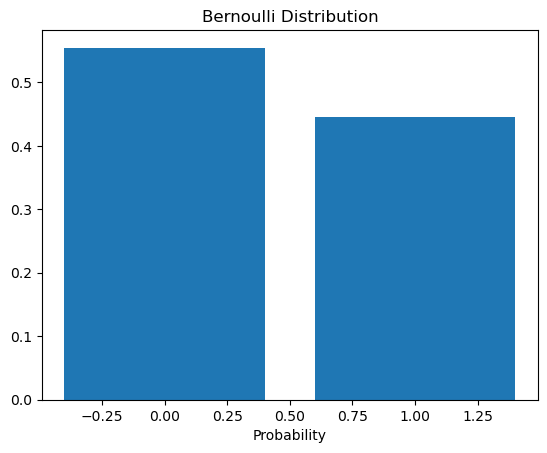





No. of Trials : 9
Mean : 2.8545454545454545
Probability : [3.22703378e-02 1.34905288e-01 2.50652429e-01 2.71663727e-01
 1.89280496e-01 8.79202305e-02 2.72257913e-02 5.41984264e-03
 6.29375218e-04 3.24825474e-05]


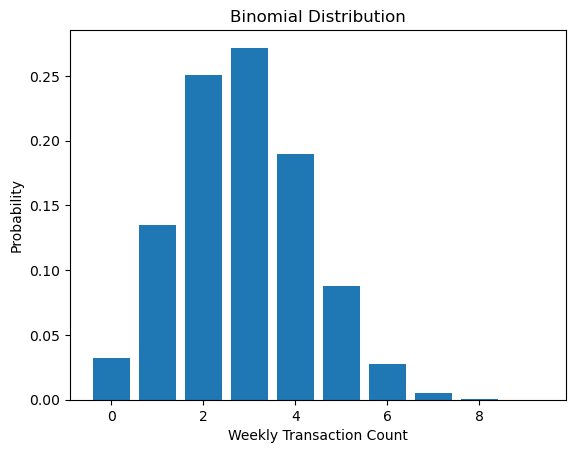

In [15]:
# Bernoulli Distribution

p = (Status == "Success").mean()
q = 1 - p
print(f"Success Probability : {p}%")
print(f"Failure Probability : {q}%")

X = [0 , 1]

P = bernoulli.pmf(X , p)

# Chart
plt.bar(X , P)

plt.xlabel("Outcome")
plt.xlabel("Probability")
plt.title("Bernoulli Distribution")
plt.savefig("PR_3_Charts/Bernoulli.png" , dpi = 300 , bbox_inches = "tight")
plt.show()


# -----------------------------------------------------------------------------------------------------------------------------------------------------

print("\n\n" , "=" * 150)
# Binomial Distribution

n = 9
Mean = Count.mean()

p_bi = Mean / n
X_bi = np.arange(0, n + 1)

P_bi = binom.pmf(X_bi , n , p_bi)
print(f"\n\nNo. of Trials : {n}")
print(f"Mean : {Mean}")
print(f"Probability : {P_bi}")

# Chart
plt.bar(X_bi , P_bi)
plt.xlabel("Weekly Transaction Count")
plt.ylabel("Probability")
plt.title("Binomial Distribution")
plt.savefig("PR_3_Charts/Binomial.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

# **2. Fit the data to Poisson distribution (number of transactions per day).**

Lambda : 7.096774193548387


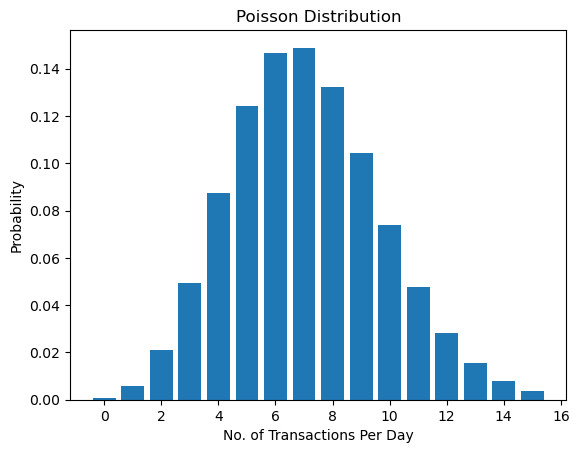

In [16]:
Daily_Count = DF.groupby(DF["transaction_date"].dt.date).size()

Lambda = Daily_Count.mean()

print(f"Lambda : {Lambda}")

X = np.arange(0 , 16)

P = poisson.pmf(X, Lambda)

# Chart
plt.bar(X , P)
plt.xlabel("No. of Transactions Per Day")
plt.ylabel("Probability")
plt.title("Poisson Distribution")
plt.savefig("PR_3_Charts/QQ_Plot.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

# **3. Model transaction amounts using Log-Normal and Power Law distributions.**

In [6]:
# Log - Normal

Shape = lognorm.fit(Amount , floc = 0)[0]
Loc = lognorm.fit(Amount , floc = 0)[1]
Scale = lognorm.fit(Amount , floc = 0)[2]

print("=" * 5 , "For Log-Normal" , "=" * 5)
print(f"\nShape : {Shape}")
print(f"Location : {Loc}")
print(f"Scale : {Scale}")


# -----------------------------------------------------------------------------------------------------------------------------------------------------


# Power Law
Shape_PL = pareto.fit(Amount , floc = 0)[0]
Loc_PL = pareto.fit(Amount , floc = 0)[1]
Scale_PL = pareto.fit(Amount , floc = 0)[2]

print("\n\n")
print("=" * 5 , "For Power Law" , "=" * 5)
print(f"\nShape : {Shape_PL}")
print(f"Location : {Loc_PL}")
print(f"Scale : {Scale_PL}")

===== For Log-Normal =====

Shape : 0.4749178350151927
Location : 0
Scale : 2983.1591334067753



===== For Power Law =====

Shape : 0.7629996393449987
Location : 0
Scale : 804.42


# **4. Generate and interpret a Q-Q Plot to test normality.**

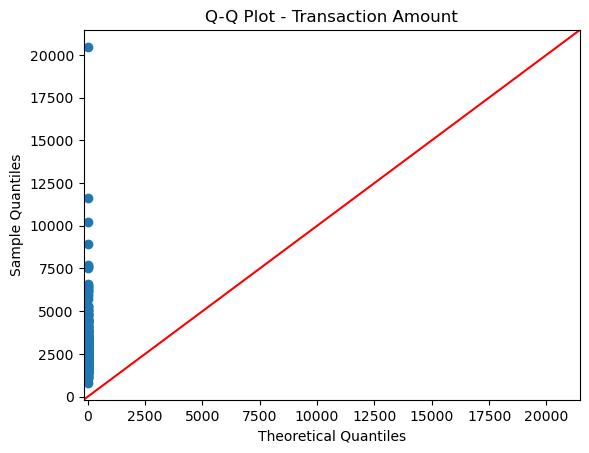

In [17]:
sm.qqplot(Amount , line = "45")

plt.title("Q-Q Plot - Transaction Amount")
plt.savefig("PR_3_Charts/QQ_Plot_Test_Normality.png")
plt.show()

# **5. Apply Box-Cox Transform to stabilize variance.**

Lambda : -0.18083390743966327
Original Skewness : 3.730109977696717
Transformed Skewness : -0.010599306471364936


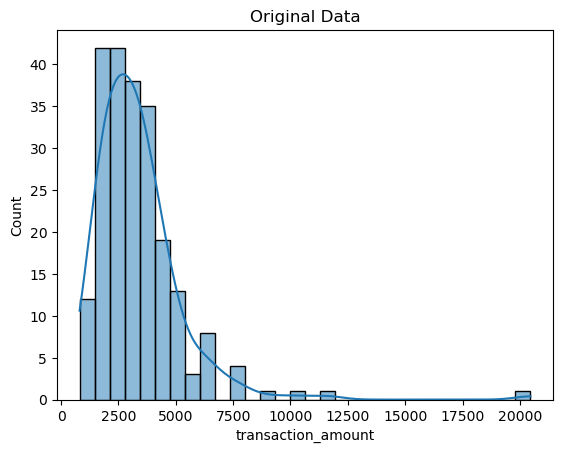

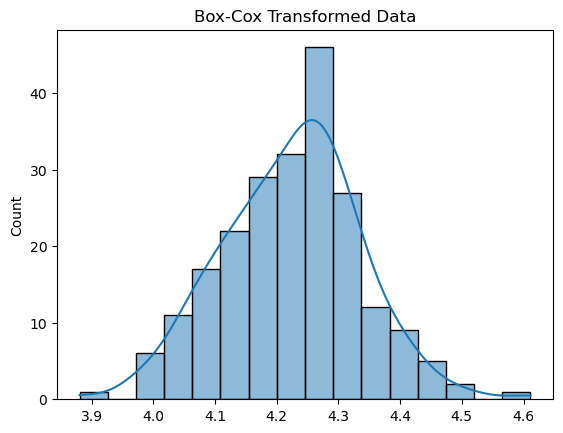

In [18]:
Transformed = stats.boxcox(Amount)[0]
Lambda = stats.boxcox(Amount)[1]

print(f"Lambda : {Lambda}")
print(f"Original Skewness : {stats.skew(Amount)}")
print(f"Transformed Skewness : {stats.skew(Transformed)}")

# Chart
# Original Data
sns.histplot(Amount , kde = True)
plt.title("Original Data")
plt.savefig("PR_3_Charts/Original.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

print("\n\n" , "=" * 150)
print("\n\n")

# Transformed Data
sns.histplot(Transformed , kde = True)
plt.title("Box-Cox Transformed Data")
plt.savefig("PR_3_Charts/Box-Cox Transform.png" , dpi = 300 , bbox_inches = "tight")
plt.show()

# **6. Calculate Z-scores for transaction amounts and compute probability of transactions exceeding ₹5000.**

In [9]:
Mean = Amount.mean()
SD = Amount.std()
X = 5000

Z = (X - Mean) / SD

print(f"Mean : {Mean}")
print(f"\nStandard Deviation : {SD}")
print(f"\nZ-score : {Z}")

# Calculate probability

P = 1 - stats.norm.cdf(Z)
print(f"\nProbability : {P}")
print(f"Percentage : {P * 100}%")


Actual_Probability = (Amount > 5000).mean()
print(f"\nActual Probability : {Actual_Probability}")
print(f"Actual Percentage : {Actual_Probability * 100}%")

Mean : 3365.1924090909088

Standard Deviation : 1985.7054091615962

Z-score : 0.8232880785671723

Probability : 0.20517209567554384
Percentage : 20.517209567554385%

Actual Probability : 0.11363636363636363
Actual Percentage : 11.363636363636363%


# **7. Plot and interpret PDF and CDF for transaction amounts.**

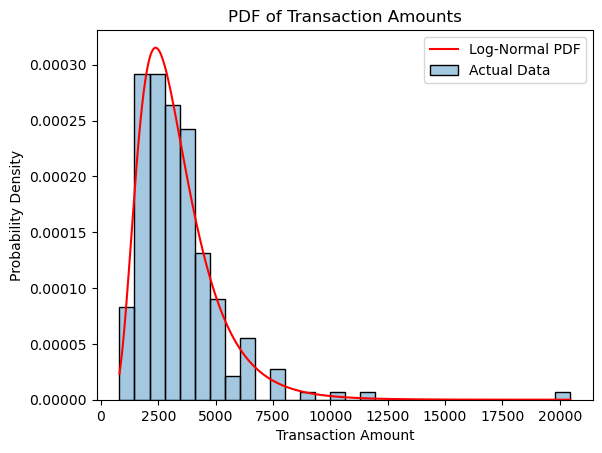

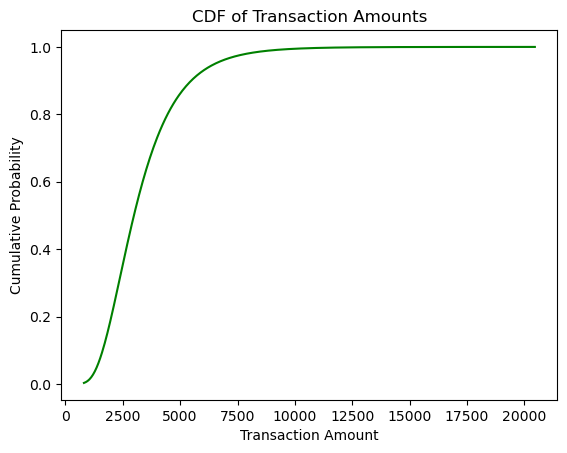

In [21]:
# PDF
Shape , Loc , Scale = lognorm.fit(Amount , floc = 0)
X = np.linspace(Amount.min() , Amount.max() , 500)
PDF = lognorm.pdf(X , Shape , Loc , Scale)

# Chart
sns.histplot(Amount , stat = "density" , bins = 30 , alpha = 0.4 , label = "Actual Data")
plt.plot(X , PDF , color = "red" , label = "Log-Normal PDF")
plt.xlabel("Transaction Amount")
plt.ylabel("Probability Density")
plt.title("PDF of Transaction Amounts")
plt.legend()
plt.savefig("PR_3_Charts/PDF.png" , dpi = 30 , bbox_inches = "tight")
plt.show()


# -----------------------------------------------------------------------------------------------------------------------------------------------------


# CDF
print("\n\n" , "=" * 150)
print("\n\n")
CDF = lognorm.cdf(X , Shape , Loc , Scale)
plt.plot(X , CDF , color = "green")
plt.xlabel("Transaction Amount")
plt.ylabel("Cumulative Probability")
plt.title("CDF of Transaction Amounts")
plt.savefig("PR_3_Charts/CDF.png")
plt.show()

# **8. Conclude which distribution best fits the dataset and justify insights for decision-making.**

In [11]:
# Fit Log-Normal
Shape1 = lognorm.fit(Amount , floc = 0)[0]
Loc1 = lognorm.fit(Amount , floc = 0)[1]
Scale1 = lognorm.fit(Amount , floc = 0)[2]

# Power Law
Shape2 = pareto.fit(Amount , floc = 0)[0]
Loc2 = pareto.fit(Amount , floc = 0)[1]
Scale2 = pareto.fit(Amount , floc = 0)[2]


LL1 = lognorm.logpdf(Amount , Shape1 , Loc1 , Scale1).sum()
LL2 = pareto.logpdf(Amount , Shape2 , Loc2 , Scale2).sum()


K = 2

AIC_LogNormal = (2 * K) - (2 * LL1)
AIC_PowerLaw = (2 * K) - (2 * LL2)

print(f"Log-Normal AIC : {AIC_LogNormal}")
print(f"Power Law AIC : {AIC_PowerLaw}")

Log-Normal AIC : 3821.027805464873
Power Law AIC : 4083.3437741043394
